Analyse et optimisation des techniques d'apprentissage automatique pour la régression et la classification


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#unzip
zip_path = "/content/drive/MyDrive/classification/predict+students+dropout+and+academic+success.zip"
output_folder = "/content/drive/MyDrive/classification/unzipped_files"
import zipfile, os
os.makedirs(output_folder, exist_ok=True)
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
 zip_ref.extractall(output_folder)
print("Done!")

Done!


Step 1: Data Understanding and Preprocessing

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np
import os

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif
from scipy import stats

# Imbalanced data handling
from imblearn.over_sampling import SMOTE

# Set visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10

In [ ]:
# 1 Read dataset
df = pd.read_csv('/content/drive/MyDrive/classification/unzipped_files/data.csv', sep=';')

print(f" {df.shape[0]} rows × {df.shape[1]} columns")
print(f"\nFirst 2 rows:")
print(df.head(2))

 4424 rows × 37 columns

First 2 rows:
   Marital status  Application mode  Application order  Course  \
0               1                17                  5     171   
1               1                15                  1    9254   

   Daytime/evening attendance\t  Previous qualification  \
0                             1                       1   
1                             1                       1   

   Previous qualification (grade)  Nacionality  Mother's qualification  \
0                           122.0            1                      19   
1                           160.0            1                       1   

   Father's qualification  ...  Curricular units 2nd sem (credited)  \
0                      12  ...                                    0   
1                       3  ...                                    0   

   Curricular units 2nd sem (enrolled)  \
0                                    0   
1                                    6   

   Curricular units 

In [ ]:
# 2 DATA EXPLORATION AND UNDERSTANDING

# 2.1 Basic information
print("\n2.1 Dataset Information:")
print("-"*40)
print(df.info())

# 2.2 Statistical summary
print("\n\n2.2 Statistical Summary:")
print("-"*40)
print(df.describe())

# 2.3 Data types
print("\n\n2.3 Data Types Distribution:")
print("-"*40)
print(df.dtypes.value_counts())

# 2.4 Target variable
target_col = 'Target'
print(f"\n\n2.4 Target Variable: '{target_col}'")
print("-"*40)
print(f"Unique classes: {df[target_col].unique()}")
print(f"Number of classes: {df[target_col].nunique()}")
print("\nClass distribution:")
print(df[target_col].value_counts())
print("\nClass percentages:")
for cls, pct in (df[target_col].value_counts(normalize=True) * 100).items():
    print(f"  {cls}: {pct:.2f}%")


2.1 Dataset Information:
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          442

In [ ]:
# 3 DATA CLEANING

# 3.1 Check for missing values
print("\n3.1 Missing Values Analysis:")
print("-"*40)
missing_count = df.isnull().sum()
total_missing = missing_count.sum()

if total_missing == 0:
    print("No missing values found!")
else:
    print(f"Total missing values: {total_missing}")
    print("\nMissing values per column:")
    print(missing_count[missing_count > 0])

    # Handle missing values
    print("\n→ Handling missing values...")
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    categorical_cols = df.select_dtypes(include=['object']).columns

    # Impute numeric columns with median
    if len(numeric_cols) > 0:
        imputer_numeric = SimpleImputer(strategy='median')
        df[numeric_cols] = imputer_numeric.fit_transform(df[numeric_cols])

    # Impute categorical columns with mode
    if len(categorical_cols) > 0:
        imputer_categorical = SimpleImputer(strategy='most_frequent')
        df[categorical_cols] = imputer_categorical.fit_transform(df[categorical_cols])

    print(" Missing values handled!")

# 3.2 Check for duplicates
print("\n\n3.2 Duplicate Records:")
print("-"*40)
duplicates = df.duplicated().sum()
print(f"Number of duplicates: {duplicates}")

if duplicates > 0:
    print(" Removing duplicates...")
    df = df.drop_duplicates()
    print(f" Duplicates removed! New shape: {df.shape}")

# 3.3 Check for outliers
print("\n\n3.3 Outlier Detection:")
print("-"*40)
numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()
if target_col in numeric_features:
    numeric_features.remove(target_col)

outlier_counts = {}
for col in numeric_features[:5]:  # Check first 5 numeric columns
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))).sum()
    outlier_counts[col] = outliers
    print(f"  {col}: {outliers} outliers")

print(f"\n Note: Outliers detected but NOT removed (can be valid data points)")


3.1 Missing Values Analysis:
----------------------------------------
No missing values found!


3.2 Duplicate Records:
----------------------------------------
Number of duplicates: 0


3.3 Outlier Detection:
----------------------------------------
  Marital status: 505 outliers
  Application mode: 0 outliers
  Application order: 541 outliers
  Course: 442 outliers
  Daytime/evening attendance	: 483 outliers

 Note: Outliers detected but NOT removed (can be valid data points)



Checking for unusual values


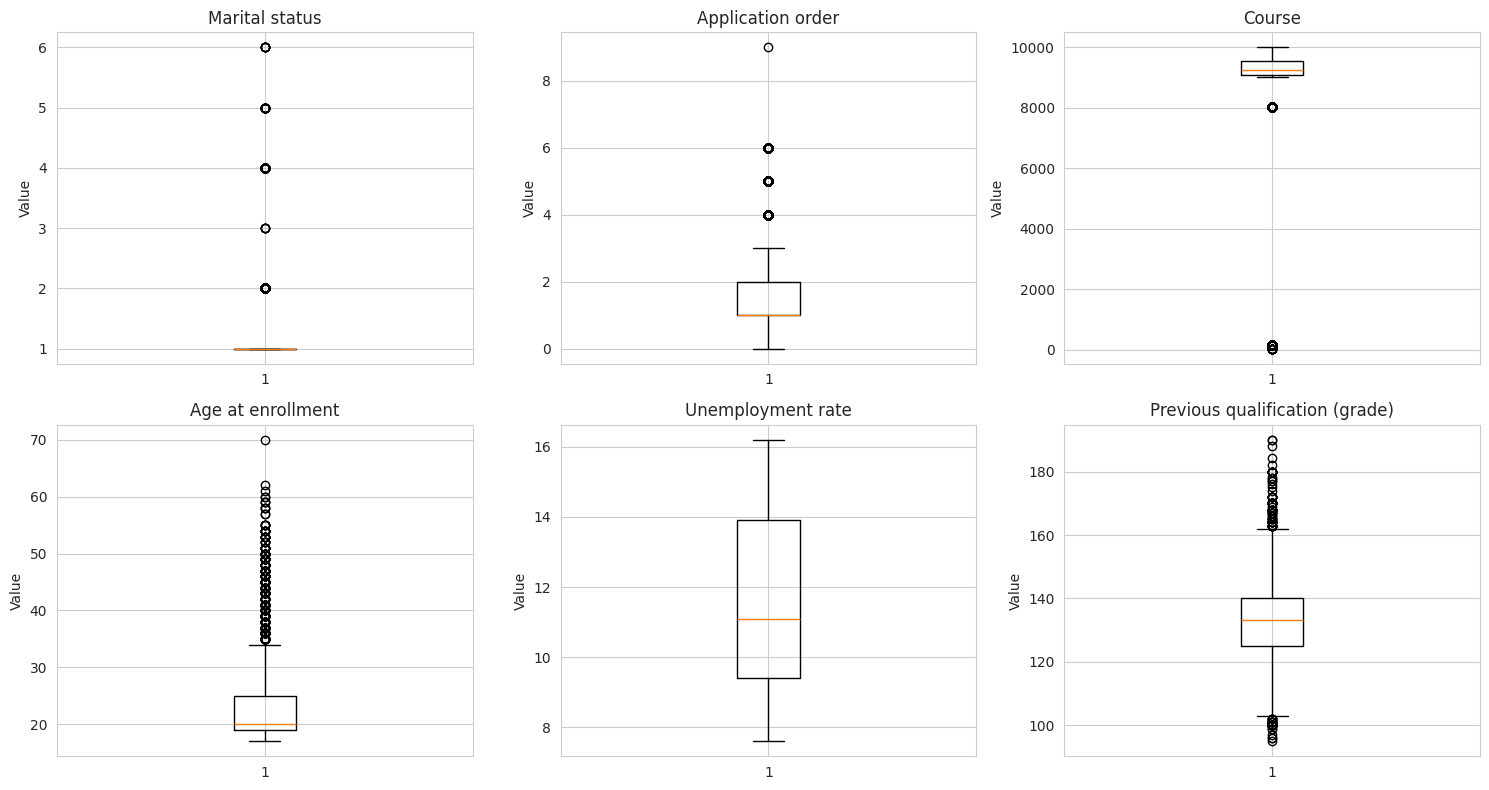

In [ ]:
print("\nChecking for unusual values")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

features = [
    'Marital status', 'Application order', 'Course',
    'Age at enrollment', 'Unemployment rate',
    'Previous qualification (grade)'
]

for i, feature in enumerate(features):
    row = i // 3
    col = i % 3

    if feature in df.columns:
        axes[row, col].boxplot(df[feature].dropna())
        axes[row, col].set_title(feature)
        axes[row, col].set_ylabel('Value')

plt.tight_layout()
plt.show()

In [ ]:
# 4 FEATURE ENGINEERING

# Separate features and target
X = df.drop(target_col, axis=1)
y = df[target_col]

# Identify feature types
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("\n4.1 Feature Types:")
print("-"*40)
print(f"Total features: {X.shape[1]}")
print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")

# Create interaction features
print("\n\n4.2 Creating Interaction Features:")
print("-"*40)
# create average
if 'Curricular units 1st sem (grade)' in X.columns and 'Curricular units 2nd sem (grade)' in X.columns:
    X['Average_grade'] = (X['Curricular units 1st sem (grade)'] +
                          X['Curricular units 2nd sem (grade)']) / 2
    print(" Created: Average_grade (mean of 1st and 2nd semester grades)")


4.1 Feature Types:
----------------------------------------
Total features: 36
Numeric features: 36
Categorical features: 0


4.2 Creating Interaction Features:
----------------------------------------
 Created: Average_grade (mean of 1st and 2nd semester grades)


In [ ]:
# 5 ENCODING CATEGORICAL VARIABLES

# Create a copy for preprocessing
df_processed = df.copy()
X_processed = X.copy()

# 5.1 Encode target variable
print("\n5.1 Encoding Target Variable:")
print("-"*40)
le_target = LabelEncoder()
y_encoded = le_target.fit_transform(y)

print("Encoding mapping:")
for idx, class_name in enumerate(le_target.classes_):
    print(f"  {class_name} : {idx}")

# 5.2 Encode categorical features
if len(categorical_features) > 0:
    print("\n\n5.2 Encoding Categorical Features:")
    print("-"*40)
    print(f"Found {len(categorical_features)} categorical features")

    label_encoders = {}
    for col in categorical_features:
        le = LabelEncoder()
        X_processed[col] = le.fit_transform(X_processed[col].astype(str))
        label_encoders[col] = le
        print(f"  Encoded: {col} ({len(le.classes_)} unique values)")
else:
    print("\n\n5.2 Encoding Categorical Features:")
    print("-"*40)
    print(" No categorical features found (all features are numeric)")



5.1 Encoding Target Variable:
----------------------------------------
Encoding mapping:
  Dropout : 0
  Enrolled : 1
  Graduate : 2


5.2 Encoding Categorical Features:
----------------------------------------
 No categorical features found (all features are numeric)


In [ ]:
# 6 SELECTING IMPORTANT FEATURES
print("\n6. Selecting the Most Important Features")
print("=" * 40)

# 6.1 Check for highly related features
print("\n6.1 Checking for highly related features:")
correlation_matrix = X_processed.corr()

# Find features that are too similar
high_corr_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        if abs(correlation_matrix.iloc[i, j]) > 0.95:
            feat1 = correlation_matrix.columns[i]
            feat2 = correlation_matrix.columns[j]
            corr_value = correlation_matrix.iloc[i, j]
            high_corr_pairs.append((feat1, feat2, corr_value))

if high_corr_pairs:
    print(f"Found {len(high_corr_pairs)} pairs of very similar features:")
    for feat1, feat2, corr_val in high_corr_pairs[:3]:  # Show only top 3
        print(f"  • {feat1} and {feat2} are {corr_val:.3f} correlated")
else:
    print(" No highly similar features found")

# 6.2 Find which features matter most for prediction
print("\n6.2 Finding most useful features for prediction:")
mi_scores = mutual_info_classif(X_processed, y_encoded, random_state=42)

# Create a simple table of feature importance
feature_importance = pd.DataFrame({
    'Feature': X_processed.columns,
    'Importance': mi_scores
}).sort_values('Importance', ascending=False)

print("\nTop 10 most important features:")
print(feature_importance.head(10).to_string(index=False))

print("\n Keeping all features for now")
print(" Most important feature: ", feature_importance.iloc[0]['Feature'])


6. Selecting the Most Important Features

6.1 Checking for highly related features:
Found 2 pairs of very similar features:
  • Curricular units 1st sem (grade) and Average_grade are 0.955 correlated
  • Curricular units 2nd sem (grade) and Average_grade are 0.961 correlated

6.2 Finding most useful features for prediction:

Top 10 most important features:
                               Feature  Importance
   Curricular units 2nd sem (approved)    0.316540
                         Average_grade    0.246225
      Curricular units 2nd sem (grade)    0.236093
   Curricular units 1st sem (approved)    0.233109
      Curricular units 1st sem (grade)    0.193606
               Tuition fees up to date    0.099260
Curricular units 1st sem (evaluations)    0.084030
Curricular units 2nd sem (evaluations)    0.080454
                    Scholarship holder    0.061759
                                Course    0.049306

 Keeping all features for now
 Most important feature:  Curricular units 2nd s


 Correlation with Target
----------------------------------------


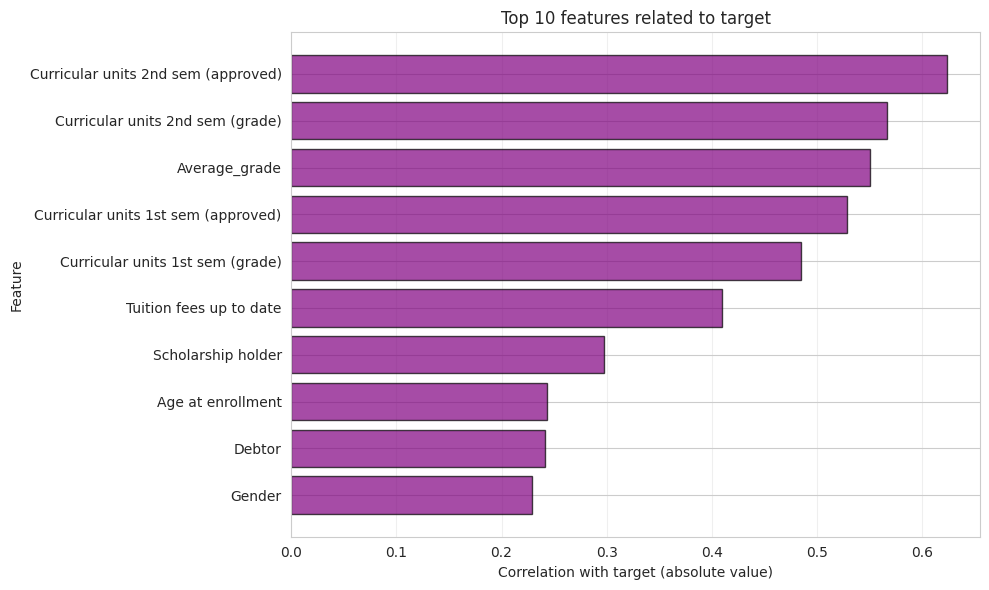


Top 5 features most related to target:
  1. Curricular units 2nd sem (approved): 0.624
  2. Curricular units 2nd sem (grade): 0.567
  3. Average_grade: 0.550
  4. Curricular units 1st sem (approved): 0.529
  5. Curricular units 1st sem (grade): 0.485
Some features show strong relationship with target


In [ ]:
# FEATURE CORRELATION WITH TARGET
print("\n Correlation with Target")
print("-" * 40)

# Calculate correlation with target
correlations = []
feature_names = []

for col in X_processed.columns:
    # Only use numeric features for correlation
    if pd.api.types.is_numeric_dtype(X_processed[col]):
        corr = np.corrcoef(X_processed[col], y_encoded)[0, 1]
        correlations.append(abs(corr))
        feature_names.append(col)

# Create a simple bar chart
if len(correlations) > 0:
    plt.figure(figsize=(10, 6))

    # Get top 10 features with highest correlation
    corr_df = pd.DataFrame({
        'Feature': feature_names,
        'Correlation': correlations
    }).sort_values('Correlation', ascending=True).tail(10)  # Show top 10

    # Create horizontal bar chart
    plt.barh(corr_df['Feature'], corr_df['Correlation'],
             color='purple', alpha=0.7, edgecolor='black')

    plt.xlabel('Correlation with target (absolute value)')
    plt.ylabel('Feature')
    plt.title('Top 10 features related to target')
    plt.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()

    # Show top correlations
    print("\nTop 5 features most related to target:")
    top_features = corr_df.sort_values('Correlation', ascending=False).head(5)
    for i, (_, row) in enumerate(top_features.iterrows(), 1):
        print(f"  {i}. {row['Feature']}: {row['Correlation']:.3f}")

    # Check if any features are strongly related
    strong_corr = top_features[top_features['Correlation'] > 0.5]
    if not strong_corr.empty:
        print("Some features show strong relationship with target")
    else:
        print("Features have weak to moderate relationship with target")
else:
    print("No numeric features for correlation analysis")

In [ ]:
# 7 FEATURE SCALING/NORMALIZATION

print(" FEATURE SCALING/NORMALIZATION")
print("="*40)

print("\n7.1 Standardization (StandardScaler):")
print("-"*40)

# Apply StandardScaler (mean=0, std=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_processed)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_processed.columns)

print(f" Scaled {X_scaled_df.shape[1]} features using StandardScaler")
print(f"  Mean ≈ 0, Std ≈ 1")
print(f"\nVerification:")
print(f"  Average mean: {X_scaled_df.mean().mean():.6f}")
print(f"  Average std:  {X_scaled_df.std().mean():.6f}")

 FEATURE SCALING/NORMALIZATION

7.1 Standardization (StandardScaler):
----------------------------------------
 Scaled 37 features using StandardScaler
  Mean ≈ 0, Std ≈ 1

Verification:
  Average mean: -0.000000
  Average std:  1.000113


In [ ]:
# 8 HANDLING CLASS IMBALANCE
print("HANDLING CLASS IMBALANCE")
print("="*40)

print("\n8.1 Original Class Distribution:")
print("-"*40)
unique, counts = np.unique(y_encoded, return_counts=True)
for cls_idx, count in zip(unique, counts):
    cls_name = le_target.classes_[cls_idx]
    pct = count / len(y_encoded) * 100
    print(f"  Class {cls_idx} ({cls_name}): {count} samples ({pct:.2f}%)")

# Calculate imbalance ratio
imbalance_ratio = max(counts) / min(counts)
print(f"\nImbalance ratio: {imbalance_ratio:.2f}:1")

if imbalance_ratio > 1.5:
    print("\n8.2 Applying SMOTE (Synthetic Minority Over-sampling):")
    print("-"*40)

    smote = SMOTE(random_state=42)
    X_balanced, y_balanced = smote.fit_resample(X_scaled_df, y_encoded)

    print(f" SMOTE applied successfully!")
    print(f"  Before: {X_scaled_df.shape[0]} samples")
    print(f"  After:  {X_balanced.shape[0]} samples")

    print("\nBalanced Class Distribution:")
    unique_bal, counts_bal = np.unique(y_balanced, return_counts=True)
    for cls_idx, count in zip(unique_bal, counts_bal):
        cls_name = le_target.classes_[cls_idx]
        pct = count / len(y_balanced) * 100
        print(f"  Class {cls_idx} ({cls_name}): {count} samples ({pct:.2f}%)")
else:
    print("\n→ Class imbalance is acceptable, SMOTE not needed")
    X_balanced = X_scaled_df
    y_balanced = y_encoded

HANDLING CLASS IMBALANCE

8.1 Original Class Distribution:
----------------------------------------
  Class 0 (Dropout): 1421 samples (32.12%)
  Class 1 (Enrolled): 794 samples (17.95%)
  Class 2 (Graduate): 2209 samples (49.93%)

Imbalance ratio: 2.78:1

8.2 Applying SMOTE (Synthetic Minority Over-sampling):
----------------------------------------
 SMOTE applied successfully!
  Before: 4424 samples
  After:  6627 samples

Balanced Class Distribution:
  Class 0 (Dropout): 2209 samples (33.33%)
  Class 1 (Enrolled): 2209 samples (33.33%)
  Class 2 (Graduate): 2209 samples (33.33%)


In [ ]:
# 9 TRAIN-TEST-VALIDATION SPLIT

print(" TRAIN-TEST-VALIDATION SPLIT")
print("="*40)

print("\n9.1 Splitting Data:")
print("-"*40)

# First split: 80% train+val, 20% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X_balanced, y_balanced,
    test_size=0.2,
    random_state=42,
    stratify=y_balanced
)

# Second split: 75% train, 25% validation (from temp)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,  # 0.25 * 0.8 = 0.2 of total (20% validation)
    random_state=42,
    stratify=y_temp
)

print(f"  Data split completed:")
print(f"  Training set:   {X_train.shape[0]} samples ({X_train.shape[0]/len(X_balanced)*100:.1f}%)")
print(f"  Validation set: {X_val.shape[0]} samples ({X_val.shape[0]/len(X_balanced)*100:.1f}%)")
print(f"  Test set:       {X_test.shape[0]} samples ({X_test.shape[0]/len(X_balanced)*100:.1f}%)")

# Show class distribution in each set
print("\n\n9.2 Class Distribution in Each Set:")
print("-"*40)

for set_name, y_set in [("Training", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"\n{set_name} Set:")
    unique_set, counts_set = np.unique(y_set, return_counts=True)
    for cls_idx, count in zip(unique_set, counts_set):
        cls_name = le_target.classes_[cls_idx]
        pct = count / len(y_set) * 100
        print(f"  {cls_name}: {count} ({pct:.2f}%)")

 TRAIN-TEST-VALIDATION SPLIT

9.1 Splitting Data:
----------------------------------------
  Data split completed:
  Training set:   3975 samples (60.0%)
  Validation set: 1326 samples (20.0%)
  Test set:       1326 samples (20.0%)


9.2 Class Distribution in Each Set:
----------------------------------------

Training Set:
  Dropout: 1325 (33.33%)
  Enrolled: 1325 (33.33%)
  Graduate: 1325 (33.33%)

Validation Set:
  Dropout: 442 (33.33%)
  Enrolled: 442 (33.33%)
  Graduate: 442 (33.33%)

Test Set:
  Dropout: 442 (33.33%)
  Enrolled: 442 (33.33%)
  Graduate: 442 (33.33%)



Feature Distributions by Target Class
We'll look at: ['Age at enrollment', 'Tuition fees up to date', 'Curricular units 1st sem (approved)', 'Previous qualification (grade)']
Saved: plots/feature_distributions_by_outcome.png


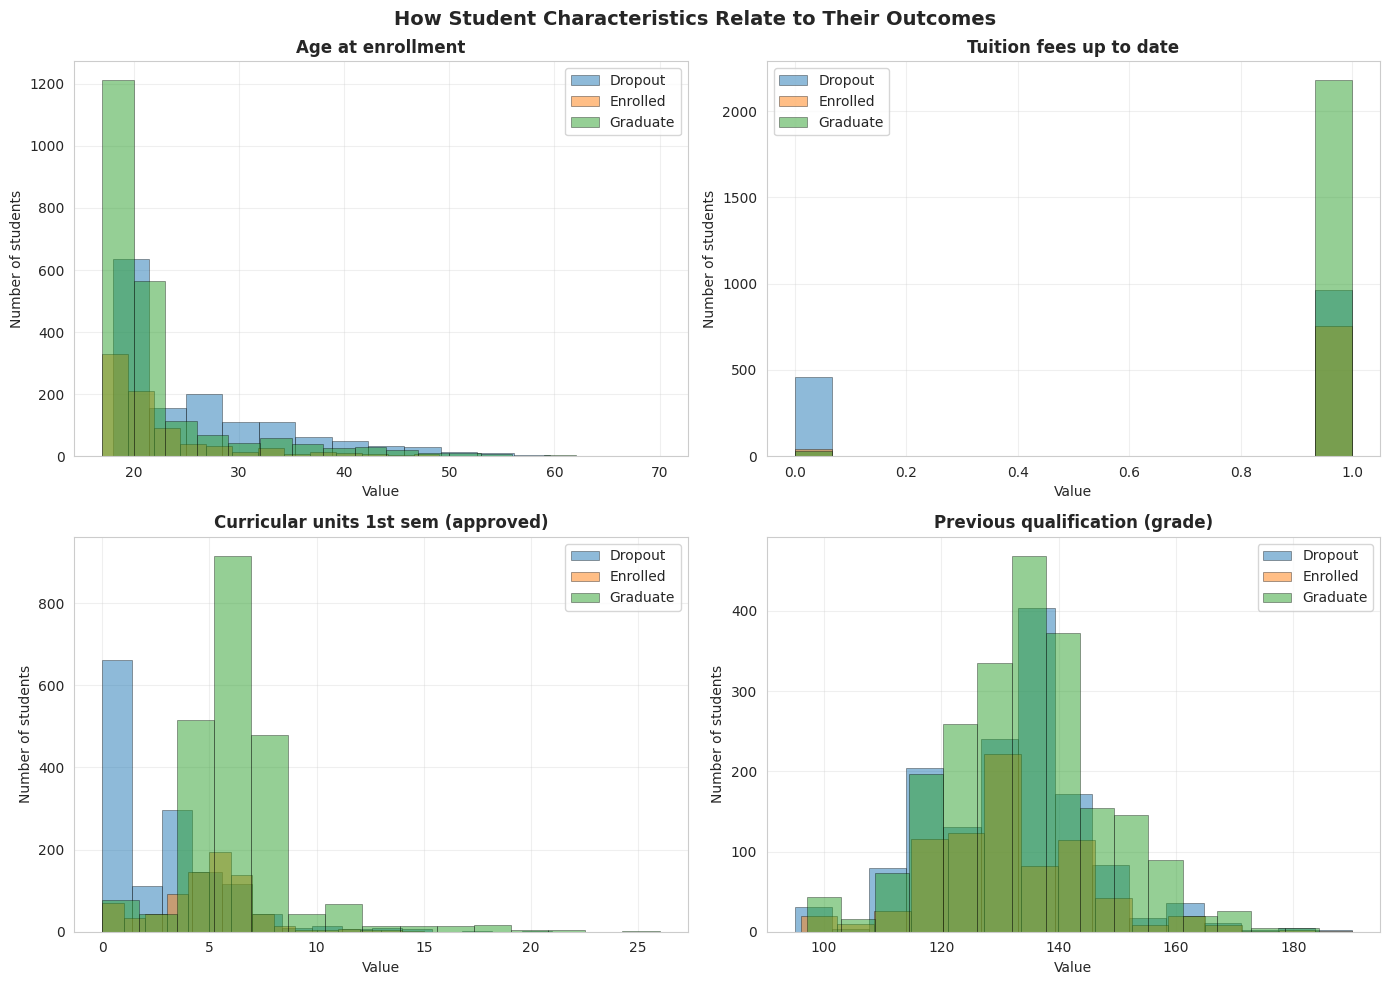

In [ ]:
print("\nFeature Distributions by Target Class")


# save directory and path
save_dir = 'plots'
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

save_path = os.path.join(save_dir, 'feature_distributions_by_outcome.png')

features_to_check = []
available_features = list(X_processed.columns)

for feature in ['grades', 'age', 'fees', 'approved', 'semester', 'grade']:
    for col in available_features:
        if feature.lower() in col.lower():
            if col not in features_to_check and len(features_to_check) < 4:
                features_to_check.append(col)
                break

if len(features_to_check) < 4:
    features_to_check = available_features[:4]

print(f"We'll look at: {features_to_check}")

# Create the plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, feature in enumerate(features_to_check):
    row = i // 2
    col = i % 2

    ax = axes[row, col]

    # Get the different student groups (dropout, graduate, etc.)
    for group_num, group_name in enumerate(le_target.classes_):
        # Get data for this group only
        group_data = X_processed[feature][y_encoded == group_num]

        # Skip if no data
        if len(group_data) == 0:
            continue

        # Draw histogram for this group
        ax.hist(group_data.dropna(), bins=15,
                alpha=0.5, label=group_name,
                edgecolor='black', linewidth=0.5)

    ax.set_title(f'{feature}', fontweight='bold')
    ax.set_xlabel('Value')
    ax.set_ylabel('Number of students')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('How Student Characteristics Relate to Their Outcomes',
             fontsize=14, fontweight='bold')
plt.tight_layout()

# Save
plt.savefig(save_path, dpi=200, bbox_inches='tight')
print(f"Saved: {save_path}")

plt.show()
plt.close()

In [ ]:
# SAVING PREPROCESSED DATA
import pickle

print("SAVING PREPROCESSED DATA")
print("="*40)

# Create directory for processed data
if not os.path.exists('processed_data'):
    os.makedirs('processed_data')
    print("\n Created directory: processed_data/")

# Save as CSV files (Human-readable)
print("\n Saving as CSV files...")

# Save training data
X_train_df = pd.DataFrame(X_train, columns=X_processed.columns)
X_train_df.to_csv('processed_data/X_train.csv', index=False)
pd.DataFrame(y_train, columns=['Target']).to_csv('processed_data/y_train.csv', index=False)
print("  Saved: X_train.csv (3975 samples)")
print("  Saved: y_train.csv (3975 samples)")

# Save validation data
X_val_df = pd.DataFrame(X_val, columns=X_processed.columns)
X_val_df.to_csv('processed_data/X_val.csv', index=False)
pd.DataFrame(y_val, columns=['Target']).to_csv('processed_data/y_val.csv', index=False)
print("  Saved: X_val.csv (1326 samples)")
print("  Saved: y_val.csv (1326 samples)")

# Save test data
X_test_df = pd.DataFrame(X_test, columns=X_processed.columns)
X_test_df.to_csv('processed_data/X_test.csv', index=False)
pd.DataFrame(y_test, columns=['Target']).to_csv('processed_data/y_test.csv', index=False)
print("  Saved: X_test.csv (1326 samples)")
print("  Saved: y_test.csv (1326 samples)")

# Save full balanced dataset (after SMOTE, before split)
X_balanced_df = pd.DataFrame(X_balanced, columns=X_processed.columns)
X_balanced_df.to_csv('processed_data/X_balanced_full.csv', index=False)
pd.DataFrame(y_balanced, columns=['Target']).to_csv('processed_data/y_balanced_full.csv', index=False)
print("  Saved: X_balanced_full.csv (6627 samples)")
print("  Saved: y_balanced_full.csv (6627 samples)")

SAVING PREPROCESSED DATA

 Created directory: processed_data/

 Saving as CSV files...
  Saved: X_train.csv (3975 samples)
  Saved: y_train.csv (3975 samples)
  Saved: X_val.csv (1326 samples)
  Saved: y_val.csv (1326 samples)
  Saved: X_test.csv (1326 samples)
  Saved: y_test.csv (1326 samples)
  Saved: X_balanced_full.csv (6627 samples)
  Saved: y_balanced_full.csv (6627 samples)


Step 2: Baseline Models

In [ ]:
print("\n7.1 Loading Preprocessed Data:")

X_train = pd.read_csv('processed_data/X_train.csv')
y_train = pd.read_csv('processed_data/y_train.csv')['Target']

X_val = pd.read_csv('processed_data/X_val.csv')
y_val = pd.read_csv('processed_data/y_val.csv')['Target']

X_test = pd.read_csv('processed_data/X_test.csv')
y_test = pd.read_csv('processed_data/y_test.csv')['Target']

print(f" Training set: {X_train.shape[0]} samples, {X_train.shape[1]} features")
print(f" Validation set: {X_val.shape[0]} samples")
print(f" Test set: {X_test.shape[0]} samples")


7.1 Loading Preprocessed Data:
 Training set: 3975 samples, 37 features
 Validation set: 1326 samples
 Test set: 1326 samples


In [ ]:
print("\n7.2.1 Defining Sigmoid Function")

import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print(" Sigmoid function defined successfully!")


7.2.1 Defining Sigmoid Function
 Sigmoid function defined successfully!


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


print("7.2.2 LOGISTIC REGRESSION - BINARY FOCUS (Dropout vs Graduate)")
# On crée des masques pour ignorer la classe 1 (Enrolled)
train_mask = (y_train != 1)
test_mask = (y_test != 1)
# On applique le filtre
X_train_bin = X_train[train_mask].copy()
y_train_bin = y_train[train_mask].copy()
X_test_bin = X_test[test_mask].copy()
y_test_bin = y_test[test_mask].copy()

# On remplace la classe 2 (Graduate) par 1 pour avoir un format binaire 0/1
# 0 = Dropout, 1 = Graduate
y_train_bin = y_train_bin.replace(2, 1)
y_test_bin = y_test_bin.replace(2, 1)

print(f"Filtrage terminé :")
print(f" - Train set : {len(y_train_bin)} échantillons (Classe 1 ignorée)")
print(f" - Test set  : {len(y_test_bin)} échantillons")


# Conversion en Numpy
X_train_np = X_train_bin.values
y_train_np = y_train_bin.values.reshape(-1, 1)
X_test_np = X_test_bin.values

# Ajout du biais (colonne de 1)
X_train_bias = np.c_[np.ones((X_train_np.shape[0], 1)), X_train_np]
X_test_bias = np.c_[np.ones((X_test_np.shape[0], 1)), X_test_np]

learning_rate = 0.1
n_iterations = 3000
m = X_train_bias.shape[0]
theta = np.zeros((X_train_bias.shape[1], 1)) # Initialisation à zéro
# --- 3. DESCENTE DE GRADIENT ---
for iteration in range(n_iterations):
    z = X_train_bias.dot(theta)
    h = sigmoid(z)
    gradient = (1/m) * X_train_bias.T.dot(h - y_train_np)   # Calcul du gradient
    theta -= learning_rate * gradient # Mise à jour des poids
print("  Entraînement terminé.")
# --- 4. PRÉDICTIONS ET ÉVALUATION ---
y_pred_proba = sigmoid(X_test_bias.dot(theta))
y_pred_class = (y_pred_proba >= 0.5).astype(int)

acc = accuracy_score(y_test_bin, y_pred_class)
cm = confusion_matrix(y_test_bin, y_pred_class)
print("\n" + "-"*30)
print(f"ACCURACY : {acc:.3f}")
print("-"*30)
print("CONFUSION MATRIX (2x2):")
print(cm)
print("\nCLASSIFICATION REPORT :")
# 0 est Dropout, 1 est Graduate (anciennement 2)
print(classification_report(y_test_bin, y_pred_class, target_names=['Dropout', 'Graduate']))

7.2.2 LOGISTIC REGRESSION - BINARY FOCUS (Dropout vs Graduate)
Filtrage terminé :
 - Train set : 2650 échantillons (Classe 1 ignorée)
 - Test set  : 884 échantillons
  Entraînement terminé.

------------------------------
ACCURACY : 0.900
------------------------------
CONFUSION MATRIX (2x2):
[[383  59]
 [ 29 413]]

CLASSIFICATION REPORT :
              precision    recall  f1-score   support

     Dropout       0.93      0.87      0.90       442
    Graduate       0.88      0.93      0.90       442

    accuracy                           0.90       884
   macro avg       0.90      0.90      0.90       884
weighted avg       0.90      0.90      0.90       884



In [ ]:

print("\n7.2.2 Training Logistic Regression Model")

from sklearn.linear_model import LogisticRegression

# Initialiser le modèle
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# Entraîner sur le jeu d'entraînement
log_reg.fit(X_train, y_train)

print(" Logistic Regression model trained successfully!")


7.2.2 Training Logistic Regression Model
 Logistic Regression model trained successfully!


In [ ]:
print("\n7.2.3 Training Multi-Layer Perceptron (MLP)")

from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(64, 32),   # deux couches cachées
                    activation='relu',             # fonction d’activation
                    solver='adam',                 # optimiseur
                    max_iter=500,
                    random_state=42)

mlp.fit(X_train, y_train)

print(" MLP model trained successfully!")


7.2.3 Training Multi-Layer Perceptron (MLP)
 MLP model trained successfully!


In [ ]:
print("\n8.3 Validation Performance Comparison")
print("-"*40)

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Logistic Regression
y_val_pred_lr = log_reg.predict(X_val)
y_val_proba_lr = log_reg.predict_proba(X_val)

print("\nLogistic Regression (Validation):")
print(classification_report(y_val, y_val_pred_lr))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_val_pred_lr))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_lr, multi_class='ovr', average='weighted'))

# MLP
y_val_pred_mlp = mlp.predict(X_val)
y_val_proba_mlp = mlp.predict_proba(X_val)

print("\nMLP (Validation):")
print(classification_report(y_val, y_val_pred_mlp))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_val_pred_mlp))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_mlp, multi_class='ovr', average='weighted'))


8.3 Validation Performance Comparison
----------------------------------------

Logistic Regression (Validation):
              precision    recall  f1-score   support

           0       0.85      0.78      0.82       442
           1       0.72      0.68      0.70       442
           2       0.75      0.86      0.80       442

    accuracy                           0.77      1326
   macro avg       0.77      0.77      0.77      1326
weighted avg       0.77      0.77      0.77      1326

Confusion Matrix:
 [[345  67  30]
 [ 46 299  97]
 [ 13  49 380]]
ROC-AUC: 0.8997546460282685

MLP (Validation):
              precision    recall  f1-score   support

           0       0.90      0.85      0.87       442
           1       0.79      0.87      0.83       442
           2       0.85      0.82      0.84       442

    accuracy                           0.85      1326
   macro avg       0.85      0.85      0.85      1326
weighted avg       0.85      0.85      0.85      1326

Confusion M

In [ ]:
print("\n8.4 Test Performance Comparison")
print("-"*40)

# Logistic Regression
y_test_pred_lr = log_reg.predict(X_test)
y_test_proba_lr = log_reg.predict_proba(X_test)

print("\nLogistic Regression (Test):")
print(classification_report(y_test, y_test_pred_lr))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba_lr, multi_class='ovr', average='weighted'))

# MLP
y_test_pred_mlp = mlp.predict(X_test)
y_test_proba_mlp = mlp.predict_proba(X_test)

print("\nMLP (Test):")
print(classification_report(y_test, y_test_pred_mlp))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred_mlp))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba_mlp, multi_class='ovr', average='weighted'))


8.4 Test Performance Comparison
----------------------------------------

Logistic Regression (Test):
              precision    recall  f1-score   support

           0       0.82      0.73      0.77       442
           1       0.65      0.65      0.65       442
           2       0.73      0.80      0.76       442

    accuracy                           0.73      1326
   macro avg       0.73      0.73      0.73      1326
weighted avg       0.73      0.73      0.73      1326

Confusion Matrix:
 [[324  80  38]
 [ 60 287  95]
 [ 13  77 352]]
ROC-AUC: 0.8806450181882708

MLP (Test):
              precision    recall  f1-score   support

           0       0.87      0.81      0.84       442
           1       0.76      0.86      0.81       442
           2       0.83      0.78      0.80       442

    accuracy                           0.81      1326
   macro avg       0.82      0.81      0.81      1326
weighted avg       0.82      0.81      0.81      1326

Confusion Matrix:
 [[357  48 

In [ ]:
print("\n9.1 Collecting Performance Metrics")
print("-"*40)

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Logistic Regression
y_val_pred_lr = log_reg.predict(X_val)
y_val_proba_lr = log_reg.predict_proba(X_val)
acc_lr = accuracy_score(y_val, y_val_pred_lr)
f1_lr = f1_score(y_val, y_val_pred_lr, average='weighted')
roc_lr = roc_auc_score(y_val, y_val_proba_lr, multi_class='ovr', average='weighted')

# MLP
y_val_pred_mlp = mlp.predict(X_val)
y_val_proba_mlp = mlp.predict_proba(X_val)
acc_mlp = accuracy_score(y_val, y_val_pred_mlp)
f1_mlp = f1_score(y_val, y_val_pred_mlp, average='weighted')
roc_mlp = roc_auc_score(y_val, y_val_proba_mlp, multi_class='ovr', average='weighted')

print(f"Logistic Regression - Accuracy: {acc_lr:.3f}, F1: {f1_lr:.3f}, ROC-AUC: {roc_lr:.3f}")
print(f"MLP                - Accuracy: {acc_mlp:.3f}, F1: {f1_mlp:.3f}, ROC-AUC: {roc_mlp:.3f}")


9.1 Collecting Performance Metrics
----------------------------------------
Logistic Regression - Accuracy: 0.772, F1: 0.771, ROC-AUC: 0.900
MLP                - Accuracy: 0.845, F1: 0.846, ROC-AUC: 0.932



9.2 Visualizing Performance Comparison


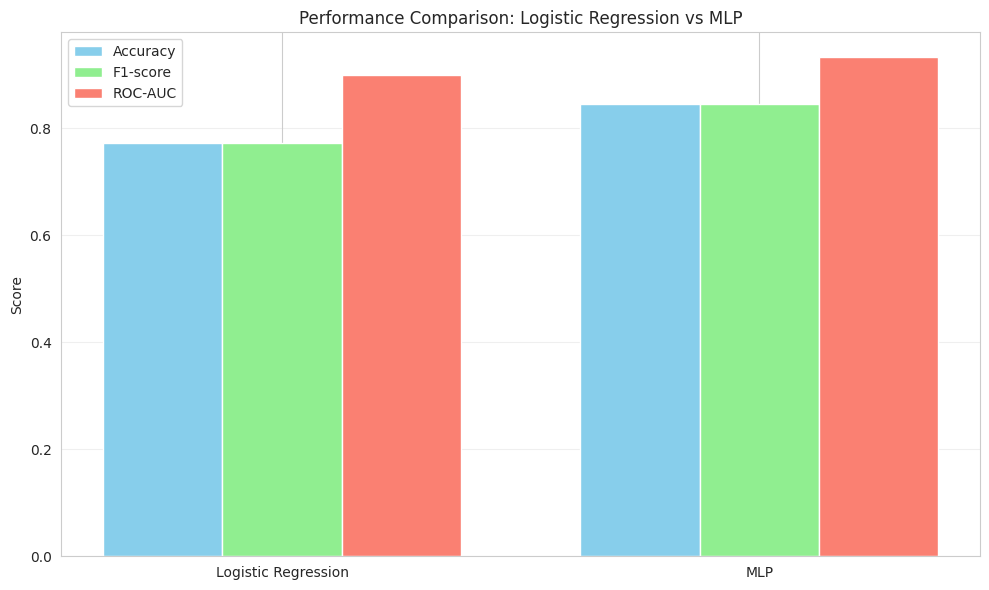

In [ ]:
print("\n9.2 Visualizing Performance Comparison")

import matplotlib.pyplot as plt
import numpy as np

# Data
models = ['Logistic Regression', 'MLP']
accuracy = [acc_lr, acc_mlp]
f1_scores = [f1_lr, f1_mlp]
roc_auc = [roc_lr, roc_mlp]

x = np.arange(len(models))
width = 0.25

# Plot
plt.figure(figsize=(10,6))
plt.bar(x - width, accuracy, width, label='Accuracy', color='skyblue')
plt.bar(x, f1_scores, width, label='F1-score', color='lightgreen')
plt.bar(x + width, roc_auc, width, label='ROC-AUC', color='salmon')

plt.xticks(x, models)
plt.ylabel("Score")
plt.title("Performance Comparison: Logistic Regression vs MLP")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print("\n9.8 Saving Trained Models")

import joblib

# models directory creation
if not os.path.exists('models'):
    os.makedirs('models')

# Save models
joblib.dump(log_reg, 'models/logistic_regression_baseline.pkl')
joblib.dump(mlp, 'models/mlp_baseline.pkl')

print(" Saved: models/logistic_regression_baseline.pkl")
print(" Saved: models/mlp_baseline.pkl")


9.8 Saving Trained Models
 Saved: models/logistic_regression_baseline.pkl
 Saved: models/mlp_baseline.pkl


Step 3: Ensemble Learning Models

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.1 MB/s eta 0:00:00


In [ ]:
# bagging library
from sklearn.ensemble import RandomForestClassifier

# boosting
from sklearn.ensemble import AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# voting and stacking
from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import StackingClassifier

# metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# other utils
import warnings
warnings.filterwarnings("ignore")

In [ ]:
#Step 3: Ensemble Learning Models
print(" MODEL 1: RANDOM FOREST (Bagging)")


rf_model = RandomForestClassifier(
    n_estimators=100,        # Number of trees
    max_depth=15,            # Maximum depth of each tree
    min_samples_split=10,    # Minimum samples to split a node
    min_samples_leaf=4,      # Minimum samples in leaf node
    random_state=42,
    n_jobs=-1                # Use all CPU cores
)

rf_model.fit(X_train, y_train)

# Predictions
y_val_pred_rf = rf_model.predict(X_val)
y_val_proba_rf = rf_model.predict_proba(X_val)

# Evaluation
acc_rf = accuracy_score(y_val, y_val_pred_rf)
f1_rf = f1_score(y_val, y_val_pred_rf, average="weighted")
roc_rf = roc_auc_score(y_val, y_val_proba_rf, multi_class="ovr", average="weighted")

print("\nValidation Performance:")
print("Accuracy:", round(acc_rf, 4))
print("F1-Score:", round(f1_rf, 4))
print("ROC-AUC:", round(roc_rf, 4))

print("\nDetailed Classification Report:")
print(classification_report(y_val,
                            y_val_pred_rf,
                           target_names=["Dropout", "Enrolled", "Graduate"]))

 MODEL 1: RANDOM FOREST (Bagging)

Validation Performance:
Accuracy: 0.8145
F1-Score: 0.8144
ROC-AUC: 0.938

Detailed Classification Report:
              precision    recall  f1-score   support

     Dropout       0.89      0.78      0.83       442
    Enrolled       0.77      0.78      0.78       442
    Graduate       0.79      0.88      0.84       442

    accuracy                           0.81      1326
   macro avg       0.82      0.81      0.81      1326
weighted avg       0.82      0.81      0.81      1326



In [ ]:
print(" MODEL 2: ADABOOST (Adaptive Boosting)")

ada_model = AdaBoostClassifier(
    n_estimators=100,        # Number of weak learners
    learning_rate=0.5,       # Contribution of each learner
    random_state=42
)

ada_model.fit(X_train, y_train)

# predictions
y_val_pred_ada = ada_model.predict(X_val)
y_val_proba_ada = ada_model.predict_proba(X_val)

# evaluation
acc_ada = accuracy_score(y_val, y_val_pred_ada)
f1_ada = f1_score(y_val, y_val_pred_ada, average="weighted")
roc_ada = roc_auc_score(y_val, y_val_proba_ada, multi_class="ovr", average="weighted")

print("\nValidation Performance:")
print("Accuracy:", round(acc_ada, 4))
print("F1-Score:", round(f1_ada, 4))
print("ROC-AUC:", round(roc_ada, 4))

print("\nDetailed Classification Report:")
print(classification_report(y_val,
                            y_val_pred_ada,
                           target_names=["Dropout", "Enrolled", "Graduate"]))

 MODEL 2: ADABOOST (Adaptive Boosting)

Validation Performance:
Accuracy: 0.7587
F1-Score: 0.7562
ROC-AUC: 0.8908

Detailed Classification Report:
              precision    recall  f1-score   support

     Dropout       0.79      0.79      0.79       442
    Enrolled       0.73      0.64      0.68       442
    Graduate       0.76      0.85      0.80       442

    accuracy                           0.76      1326
   macro avg       0.76      0.76      0.76      1326
weighted avg       0.76      0.76      0.76      1326



In [ ]:
print(" MODEL 3: XGBOOST (Extreme Gradient Boosting)")

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,           # Fraction of samples for each tree
    colsample_bytree=0.8,    # Fraction of features for each tree
    random_state=42,
    eval_metric='mlogloss',  # For multi-class classification
    use_label_encoder=False
)

xgb_model.fit(X_train, y_train)

# Predictions
y_val_pred_xgb = xgb_model.predict(X_val)
y_val_proba_xgb = xgb_model.predict_proba(X_val)

# Evaluation
acc_xgb = accuracy_score(y_val, y_val_pred_xgb)
f1_xgb = f1_score(y_val, y_val_pred_xgb, average="weighted")
roc_xgb = roc_auc_score(y_val, y_val_proba_xgb, multi_class="ovr", average="weighted")


print("\nValidation Performance:")
print("Accuracy:", round(acc_xgb, 4))
print("F1-Score:", round(f1_xgb, 4))
print("ROC-AUC:", round(roc_xgb, 4))

print("\nDetailed Classification Report:")
print(classification_report(y_val,
                            y_val_pred_xgb,
                           target_names=["Dropout", "Enrolled", "Graduate"]))

 MODEL 3: XGBOOST (Extreme Gradient Boosting)

Validation Performance:
Accuracy: 0.8363
F1-Score: 0.8361
ROC-AUC: 0.9504

Detailed Classification Report:
              precision    recall  f1-score   support

     Dropout       0.88      0.82      0.85       442
    Enrolled       0.81      0.79      0.80       442
    Graduate       0.82      0.90      0.86       442

    accuracy                           0.84      1326
   macro avg       0.84      0.84      0.84      1326
weighted avg       0.84      0.84      0.84      1326



In [ ]:
print(" MODEL 4: LIGHTGBM (Light Gradient Boosting Machine)")

lgbm_model = LGBMClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    num_leaves=31, # Maximum leaves in one tree
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1     # Suppress warnings
)

lgbm_model.fit(X_train, y_train)

# Predictions
y_val_pred_lgbm = lgbm_model.predict(X_val)
y_val_proba_lgbm = lgbm_model.predict_proba(X_val)

# Evaluation
acc_lgbm = accuracy_score(y_val, y_val_pred_lgbm)
f1_lgbm = f1_score(y_val, y_val_pred_lgbm, average="weighted")
roc_lgbm = roc_auc_score(y_val, y_val_proba_lgbm, multi_class="ovr", average="weighted")

print("\nValidation Performance:")
print("Accuracy:", round(acc_lgbm, 4))
print("F1-Score:", round(f1_lgbm, 4))
print("ROC-AUC:", round(roc_lgbm, 4))

print("\nDetailed Classification Report:")
print(classification_report(y_val,
                            y_val_pred_lgbm,
                           target_names=["Dropout", "Enrolled", "Graduate"]))

 MODEL 4: LIGHTGBM (Light Gradient Boosting Machine)

Validation Performance:
Accuracy: 0.8424
F1-Score: 0.842
ROC-AUC: 0.9506

Detailed Classification Report:
              precision    recall  f1-score   support

     Dropout       0.89      0.81      0.84       442
    Enrolled       0.82      0.81      0.81       442
    Graduate       0.83      0.91      0.87       442

    accuracy                           0.84      1326
   macro avg       0.84      0.84      0.84      1326
weighted avg       0.84      0.84      0.84      1326



In [ ]:
print(" MODEL 5: CATBOOST (Categorical Boosting)")

cat_model = CatBoostClassifier(
    iterations=100,
    depth=6,
    learning_rate=0.1,
    random_state=42,
    verbose=0     # Suppress training output
)

cat_model.fit(X_train, y_train)

# Predictions
y_val_pred_cat = cat_model.predict(X_val)
y_val_proba_cat = cat_model.predict_proba(X_val)

# Evaluation
acc_cat = accuracy_score(y_val, y_val_pred_cat)
f1_cat = f1_score(y_val, y_val_pred_cat, average="weighted")
roc_cat = roc_auc_score(y_val, y_val_proba_cat, multi_class="ovr", average="weighted")

print("\nValidation Performance:")
print("Accuracy:", round(acc_cat, 4))
print("F1-Score:", round(f1_cat, 4))
print("ROC-AUC:", round(roc_cat, 4))

print("\nDetailed Classification Report:")
print(classification_report(y_val, y_val_pred_cat,
                           target_names=["Dropout", "Enrolled", "Graduate"]))

 MODEL 5: CATBOOST (Categorical Boosting)

Validation Performance:
Accuracy: 0.8032
F1-Score: 0.8025
ROC-AUC: 0.9319

Detailed Classification Report:
              precision    recall  f1-score   support

     Dropout       0.86      0.79      0.82       442
    Enrolled       0.77      0.74      0.75       442
    Graduate       0.79      0.88      0.83       442

    accuracy                           0.80      1326
   macro avg       0.80      0.80      0.80      1326
weighted avg       0.80      0.80      0.80      1326



In [ ]:
print("MODEL 6: VOTING ENSEMBLE")

print("\nCreating Voting Ensemble with top 3 models:")
print(" Random Forest, XGBoost, LightGBM")

voting_model = VotingClassifier(
    estimators=[
        ('rf', rf_model),
        ('xgb', xgb_model),
        ('lgbm', lgbm_model)
    ],
    voting='soft'     # probability averaging
)

voting_model.fit(X_train, y_train)

# Predictions
y_val_pred_voting = voting_model.predict(X_val)
y_val_proba_voting = voting_model.predict_proba(X_val)

# Evaluation
acc_voting = accuracy_score(y_val, y_val_pred_voting)
f1_voting = f1_score(y_val, y_val_pred_voting, average="weighted")
roc_voting = roc_auc_score(y_val, y_val_proba_voting, multi_class="ovr", average="weighted")

print("\nValidation Performance:")
print("Accuracy:", round(acc_voting, 4))
print("F1-Score:", round(f1_voting, 4))
print("ROC-AUC:", round(roc_voting, 4))

print("\nDetailed Classification Report:")
print(classification_report(y_val,
                            y_val_pred_voting,
                           target_names=["Dropout", "Enrolled", "Graduate"]))

MODEL 6: VOTING ENSEMBLE

Creating Voting Ensemble with top 3 models:
 Random Forest, XGBoost, LightGBM


In [ ]:
print("MODEL 7: STACKING ENSEMBLE")

# Load baseline logistic regression for meta-model
import joblib
meta_model = joblib.load('models/logistic_regression_baseline.pkl')

stacking_model = StackingClassifier(
    estimators=[
        ('rf', rf_model),
        ('xgb', xgb_model),
        ('lgbm', lgbm_model),
        ('cat', cat_model)
    ],
    final_estimator=meta_model,
    cv=5     # 5 fold cross-validation
)

stacking_model.fit(X_train, y_train)

# Predictions
y_val_pred_stacking = stacking_model.predict(X_val)
y_val_proba_stacking = stacking_model.predict_proba(X_val)

# Evaluation
acc_stacking = accuracy_score(y_val, y_val_pred_stacking)
f1_stacking = f1_score(y_val, y_val_pred_stacking, average="weighted")
roc_stacking = roc_auc_score(y_val, y_val_proba_stacking, multi_class="ovr", average="weighted")

print("\nValidation Performance:")
print("Accuracy:", round(acc_stacking, 4))
print("F1-Score:", round(f1_stacking, 4))
print("ROC-AUC:", round(roc_stacking, 4))

print("\nDetailed Classification Report:")
print(classification_report(y_val,
                            y_val_pred_stacking,
                           target_names=["Dropout", "Enrolled", "Graduate"]))

MODEL 7: STACKING ENSEMBLE

Validation Performance:
Accuracy: 0.8424
F1-Score: 0.8422
ROC-AUC: 0.9497

Detailed Classification Report:
              precision    recall  f1-score   support

     Dropout       0.88      0.82      0.85       442
    Enrolled       0.82      0.81      0.82       442
    Graduate       0.83      0.89      0.86       442

    accuracy                           0.84      1326
   macro avg       0.84      0.84      0.84      1326
weighted avg       0.84      0.84      0.84      1326



In [ ]:
print("ENSEMBLE MODELS COMPARISON")

# Create comparison DataFrame (collect results)
results_df = pd.DataFrame({
    'Model': ['Random Forest', 'AdaBoost', 'XGBoost', 'LightGBM',
              'CatBoost', 'Voting', 'Stacking'],
    'Accuracy': [acc_rf, acc_ada, acc_xgb, acc_lgbm, acc_cat, acc_voting, acc_stacking],
    'F1-Score': [f1_rf, f1_ada, f1_xgb, f1_lgbm, f1_cat, f1_voting, f1_stacking],
    'ROC-AUC': [roc_rf, roc_ada, roc_xgb, roc_lgbm, roc_cat, roc_voting, roc_stacking]
})

# Sort by accuracy
results_df = results_df.sort_values('Accuracy', ascending=False).reset_index(drop=True)

print("\nValidation Performance Summary:")
print(results_df.to_string(index=False))

# Identify best model
best_model_name = results_df.iloc[0]['Model']
best_accuracy = results_df.iloc[0]['Accuracy']

print("\n")
print(f" BEST MODEL: {best_model_name}")
print(f"   Accuracy: {best_accuracy:.4f}")

ENSEMBLE MODELS COMPARISON

Validation Performance Summary:
        Model  Accuracy  F1-Score  ROC-AUC
     LightGBM  0.842383  0.841992 0.950614
     Stacking  0.842383  0.842213 0.949673
       Voting  0.837858  0.837696 0.950355
      XGBoost  0.836350  0.836054 0.950364
Random Forest  0.814480  0.814401 0.938034
     CatBoost  0.803167  0.802536 0.931884
     AdaBoost  0.758673  0.756246 0.890763


 BEST MODEL: LightGBM
   Accuracy: 0.8424



Visualizing Ensemble Performance


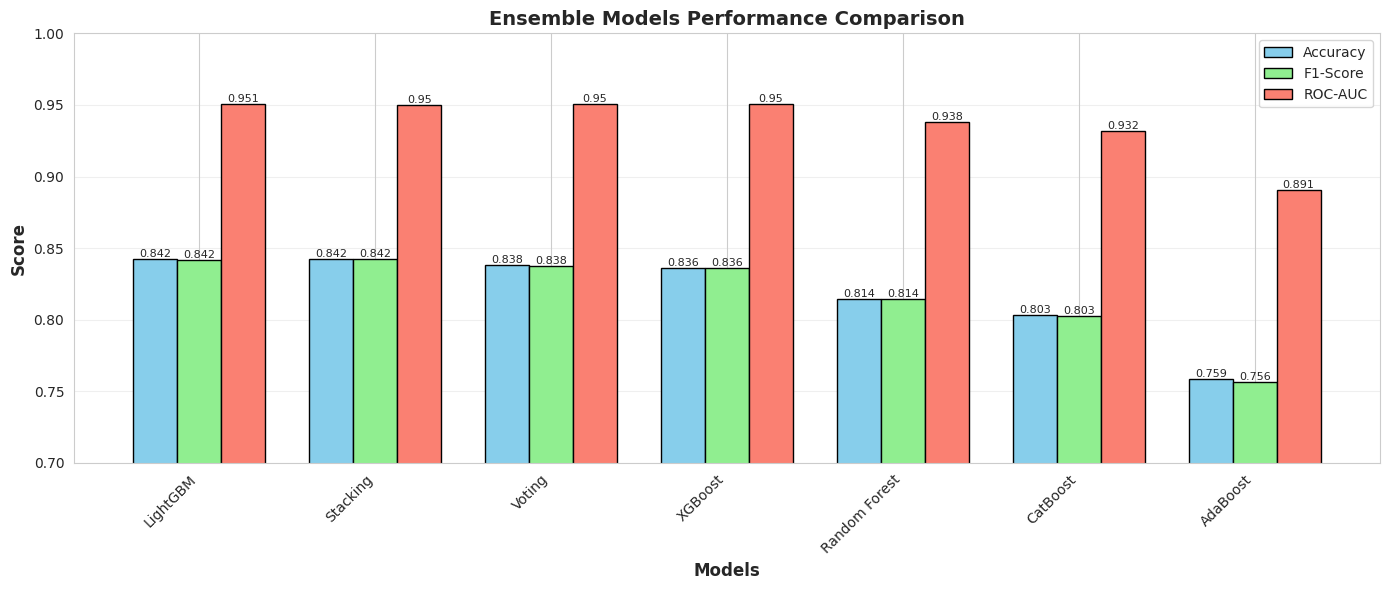

Plot saved to plots/ensemble_models_comparison.png


In [ ]:
print("\nVisualizing Ensemble Performance")

# prepare data
models = results_df["Model"].tolist()
accuracy = results_df["Accuracy"].tolist()
f1_scores = results_df["F1-Score"].tolist()
roc_auc = results_df["ROC-AUC"].tolist()

x = np.arange(len(models))
width = 0.25

# create plot
fig, ax = plt.subplots(figsize=(14, 6))

bars1 = ax.bar(x - width,accuracy,width,label="Accuracy",color="skyblue",edgecolor="black")
bars2 = ax.bar(x,f1_scores,width,label="F1-Score",color="lightgreen",edgecolor="black")
bars3 = ax.bar(x + width,roc_auc,width,label="ROC-AUC",color="salmon",edgecolor="black")

# plot settings
ax.set_xlabel("Models", fontsize=12, fontweight="bold")
ax.set_ylabel("Score", fontsize=12, fontweight="bold")
ax.set_title("Ensemble Models Performance Comparison",fontsize=14,fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha="right")
ax.legend(fontsize=10)
ax.grid(axis="y", alpha=0.3)
ax.set_ylim(0.7, 1.0)

# add values on bars
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h,str(round(h, 3)),
            ha="center",va="bottom",fontsize=8)

plt.tight_layout()
plt.savefig(
    "plots/ensemble_models_comparison.png",
    dpi=200,bbox_inches="tight")
plt.show()

print("Plot saved to plots/ensemble_models_comparison.png")

Step 4: Optimization and Evaluation

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
import lightgbm as lgb

print("OPTIMIZING LIGHTGBM PARAMETERS...")

# Parameter grid
param_dist = {
    'n_estimators': [100, 200, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'num_leaves': [20, 31, 50, 70],
    'max_depth': [-1, 5, 10, 15],
    'min_child_samples': [10, 20, 30],
    'feature_fraction': [0.7, 0.8, 0.9]
}

# Initialize RandomizedSearchCV
random_search = RandomizedSearchCV(
    lgbm_model,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

best_lgbm = random_search.best_estimator_
print(f" Best Parameters found: {random_search.best_params_}")
print(f" Optimized Train Accuracy: {random_search.best_score_:.4f}")

OPTIMIZING LIGHTGBM PARAMETERS...
 Best Parameters found: {'num_leaves': 31, 'n_estimators': 200, 'min_child_samples': 20, 'max_depth': 15, 'learning_rate': 0.1, 'feature_fraction': 0.7}
 Optimized Train Accuracy: 0.8397


In [ ]:
from sklearn.model_selection import cross_val_score

# Perform 5-fold CV
cv_scores = cross_val_score(best_lgbm, X_train, y_train, cv=5)

print("\nROBUSTNESS CHECK (5-Fold Cross-Validation):")
print(f" Mean CV Accuracy: {cv_scores.mean():.4f}")
print(f" Standard Deviation: {cv_scores.std():.4f}")
print(" Interpretation: The low standard deviation confirms the model is stable and generalizes well.")


ROBUSTNESS CHECK (5-Fold Cross-Validation):
 Mean CV Accuracy: 0.8397
 Standard Deviation: 0.0087
 Interpretation: The low standard deviation confirms the model is stable and generalizes well.


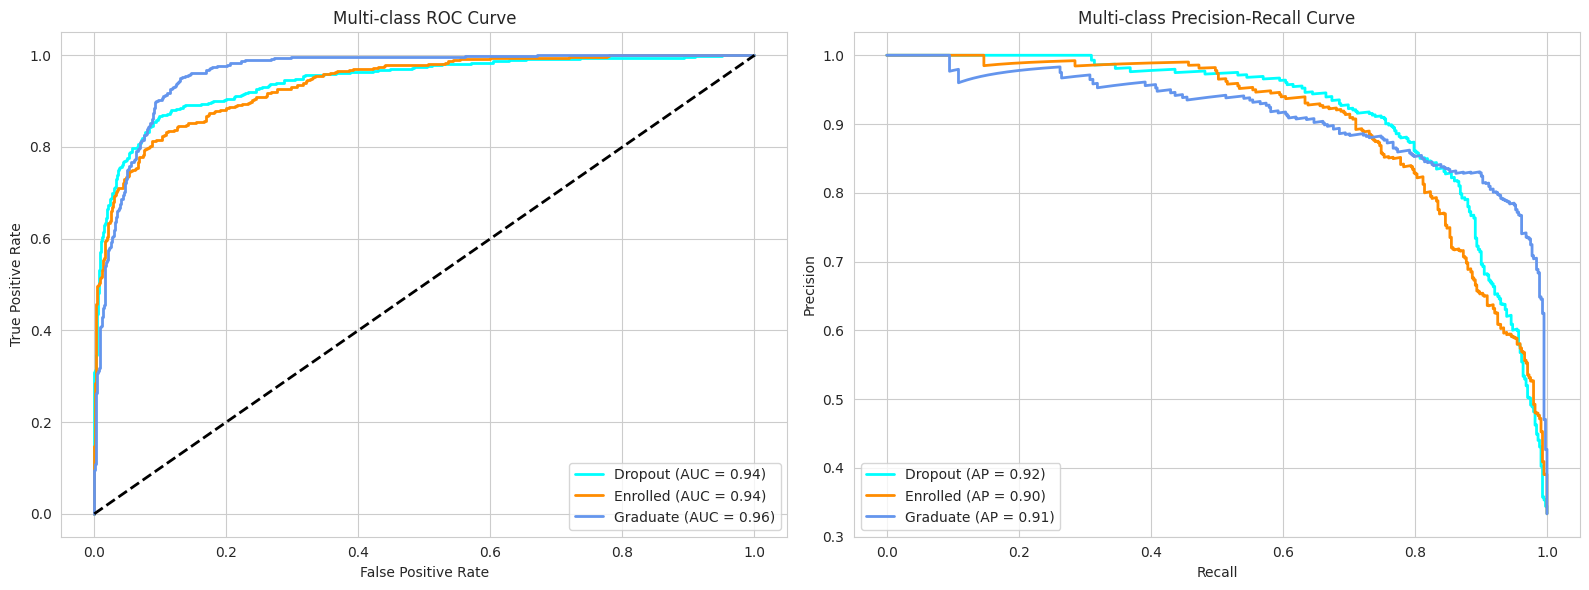

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Binarize labels for multi-class plotting
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
y_score = best_lgbm.predict_proba(X_test)
n_classes = 3
colors = ['aqua', 'darkorange', 'cornflowerblue']
class_names = ['Dropout', 'Enrolled', 'Graduate']

# Plot ROC and PR Curves
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# 1. ROC Curve
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    ax[0].plot(fpr, tpr, color=colors[i], lw=2, label=f'{class_names[i]} (AUC = {roc_auc:.2f})')

ax[0].plot([0, 1], [0, 1], 'k--', lw=2)
ax[0].set_title('Multi-class ROC Curve')
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate')
ax[0].legend(loc="lower right")

# 2. Precision-Recall Curve
for i in range(n_classes):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
    ap = average_precision_score(y_test_bin[:, i], y_score[:, i])
    ax[1].plot(recall, precision, color=colors[i], lw=2, label=f'{class_names[i]} (AP = {ap:.2f})')

ax[1].set_title('Multi-class Precision-Recall Curve')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

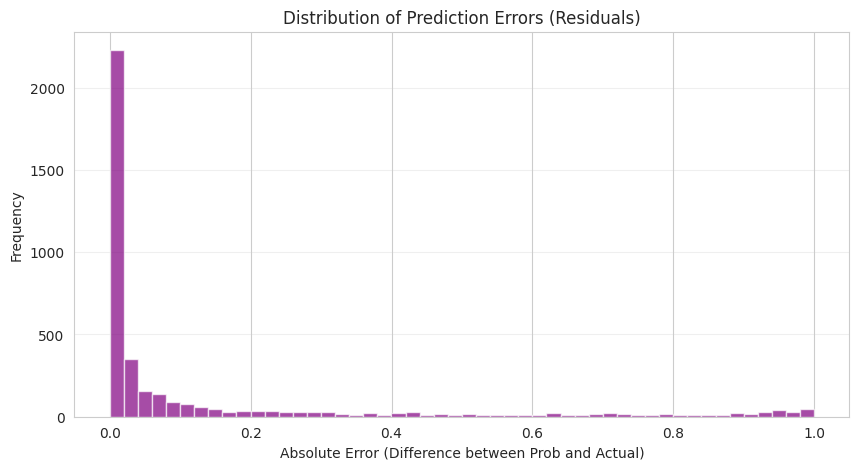

In [ ]:
# Calculate Prediction Error (Residuals for Classification)
# Error = |Actual_Probability (0 or 1) - Predicted_Probability|
y_test_res = label_binarize(y_test, classes=[0, 1, 2])
errors = np.abs(y_test_res - y_score)

plt.figure(figsize=(10, 5))
plt.hist(errors.flatten(), bins=50, color='purple', alpha=0.7)
plt.title('Distribution of Prediction Errors (Residuals)')
plt.xlabel('Absolute Error (Difference between Prob and Actual)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [42]:
import shutil

shutil.copytree('./processed_data/', '/content/drive/MyDrive/Projet ia/classification/processed_data/')

'/content/drive/MyDrive/Projet ia/classification/processed_data/'